# Reading a FEFLOW finite-element groundwater mesh

**FEFLOW** (DHI) is a finite-element simulator for subsurface flow and transport. Its classic ASCII `.fem` file carries the finite-element **mesh**: a node list plus element connectivity (here 2-D triangular elements). `pyramids-mesh` reads that mesh into a `pyramids.netcdf.ugrid.UgridDataset`, so a FEFLOW model domain becomes an ordinary pyramids object.

This sample is `disv_nodes.fem` from the MODFLOW 6 examples (the ATES heat-storage case) — a CLASS v7.501 mesh of **2496 nodes and 4842 triangles** (public-domain data).

## 2. Imports

The import below is all the setup this adds: `UgridDataset` is the object every driver hands back (a `Mesh2d` or `Network1d` wrapper). Importing from `pyramids` also puts its vendored GDAL/PROJ data in place for you, so nothing about it is order-sensitive in a notebook -- just import the names you use.

In [1]:
from pyramids.netcdf.ugrid import UgridDataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

## 3. Locate the example data

This notebook lives in `docs/examples/`, so the repo-root `examples/data/` folder is two levels up. Paths inside a notebook are written **relative to the notebook itself**. The critical rule for `read_file` is to pass a `pathlib.Path`, never `str(...)`. We read `feflow/disv_nodes.fem`.

In [2]:
from pathlib import Path
DATA = Path("../../examples/data")
mesh_file = DATA / "feflow" / "disv_nodes.fem"
mesh_file, mesh_file.exists()

(WindowsPath('../../examples/data/feflow/disv_nodes.fem'), True)

## 4. Quickstart: read the file

`UgridDataset.read_file(path, driver=...)` parses the file and returns a `UgridDataset` — the same type pyramids produces from a NetCDF UGRID file. We name the `"feflow"` driver explicitly; passing the **`Path`** object (not a string) is the supported call.

In [3]:
ds = UgridDataset.read_file(mesh_file, driver="feflow")
type(ds).__name__

'UgridDataset'

In [4]:
# reading switches matplotlib to Agg for headless safety; let cleopatra
# pick the notebook backend (inline) so the plots below embed
from cleopatra.config import Config
Config.set_matplotlib_backend()

'inline'

## 5. Explore the dataset

A `UgridDataset` exposes summary properties: `n_node` / `n_face` (mesh size), `crs` / `epsg` (georeferencing if the format recorded any), `bounds` (the `(minx, miny, maxx, maxy)` extent), and `data_variable_names` (attached field variables).

In [5]:
pd.Series({
    "n_node": ds.n_node,
    "n_face": ds.n_face,
    "crs": ds.crs,
    "epsg": ds.epsg,
    "bounds": tuple(round(float(b), 3) for b in ds.bounds),
    "data_variable_names": ds.data_variable_names,
})

n_node                                            2496
n_face                                            4842
crs                                               None
epsg                                              None
bounds                 (1000.234, 1.0, 1105.469, 51.0)
data_variable_names                                 []
dtype: object

`crs`/`epsg` are `None`: the classic FEFLOW ASCII format stores raw model coordinates. With 2496 nodes and 4842 faces this is by far the densest mesh in this set. `data_variable_names` is empty — the `.fem` file here is the mesh; simulated heads/temperatures live elsewhere.

## 6. Face-degree distribution

`ds.mesh.face_node_connectivity.data` is the `(n_face, k)` table of node indices per face, where `k` is the widest polygon. Cells with fewer nodes than `k` are **padded with `-1` (fill)**. Counting the non-negative entries per row gives each face's number of nodes — its *degree*.

In [6]:
conn = np.asarray(ds.mesh.face_node_connectivity.data)
degree = (conn >= 0).sum(axis=1)
vals, counts = np.unique(degree, return_counts=True)
dist = pd.Series(dict(zip(vals.tolist(), counts.tolist())), name="n_faces")
dist.index.name = "nodes_per_face"
{"degree_distribution": dist.to_dict(), "fill_slots(-1)": int((conn == -1).sum())}

{'degree_distribution': {3: 4842}, 'fill_slots(-1)': 0}

All 4842 elements are **3-node triangles** with no `-1` fill — a classic finite-element triangulation. Triangular elements are the FEFLOW 2-D default, so the connectivity table is dense and uniform.

## 7. The underlying geometry

`ds.mesh` is the `Mesh2d` holding the raw arrays: `node_x` / `node_y` (coordinates), the connectivity table, `face_areas` (one area per cell) and `face_centroids` (shape `(2, n_face)`). Everything geometric is derived from the connectivity plus the node coordinates.

In [7]:
mesh = ds.mesh
conn = np.asarray(mesh.face_node_connectivity.data)
areas = np.asarray(mesh.face_areas)
cent = np.asarray(mesh.face_centroids)  # (2, n_face)
{"conn_shape": conn.shape, "n_node": np.asarray(mesh.node_x).shape[0],
 "areas_minmax": (round(float(areas.min()), 4), round(float(areas.max()), 4)),
 "centroids_shape": cent.shape}

{'conn_shape': (4842, 3),
 'n_node': 2496,
 'areas_minmax': (0.0769, 5.6605),
 'centroids_shape': (2, 4842)}

## 8. Wireframe: `plot_outline()`

The simplest view needs no data — just the mesh edges. `plot_outline()` draws the wireframe through cleopatra and embeds it inline. This is the fastest sanity check that a file read in correctly.

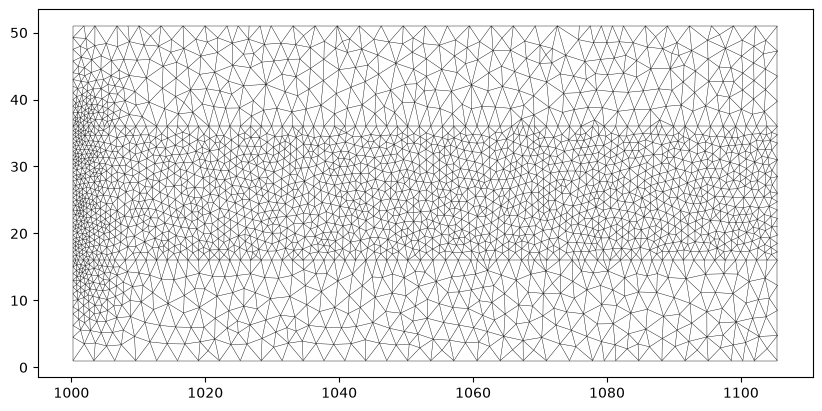

In [8]:
ds.plot_outline()


A dense, irregular triangulation refined around interior features — the hallmark of a finite-element mesh, which resolves fine detail where the physics demands it and coarsens elsewhere.

## 9. A data map: attach and colour a field

To draw a *filled* map we need a value per cell. These mesh files carry geometry only, so we compute one — each cell's area — and attach it with `with_variable(..., location="face")`, which returns a **new** dataset (the original `ds` is untouched). Then `plot` colours the mesh by it.

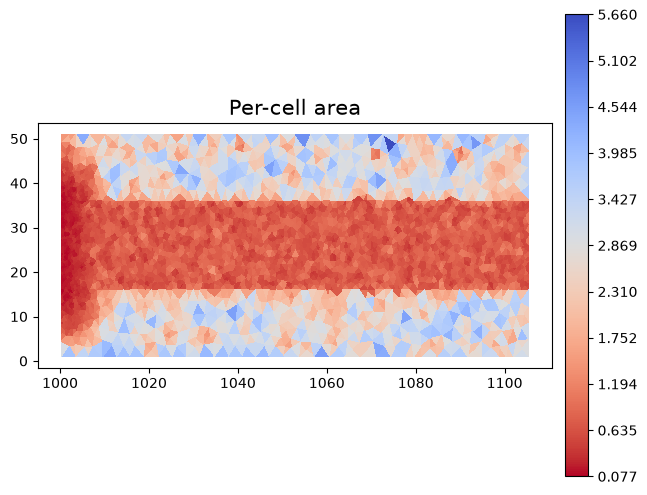

In [9]:
d2 = ds.with_variable("cell_area", np.asarray(ds.mesh.face_areas), location="face")
d2.plot("cell_area", cmap="viridis", colorbar=True, title="Per-cell area")


Each cell is now shaded by its area. This is the generic pyramids data-map path — any per-cell field (water depth, velocity, head) plots exactly the same way.

### The statistical summary

With a field attached, `.summary()` reports per-variable statistics (count, min, max, mean, std). On the bare `ds` it is an empty frame; on `d2` it has a real row.

In [10]:
d2.summary()

,count,min,max,mean,std
variable,,,,,
cell_area,4842,0.076908,5.660478,1.086683,0.934125


## 10. GIS operations, for free

Because the mesh is now a first-class pyramids object, the pyramids GIS layer applies directly — `pyramids-mesh` itself adds none of this. The next cells each run one operation and interpret it.

### Faces as a GeoDataFrame

`to_geodataframe()` turns every face into a polygon row of a geopandas `GeoDataFrame` — the standard vector structure for export to shapefile/GeoPackage or spatial joins.

In [11]:
gdf = ds.to_geodataframe()
gdf.head()

,geometry
0,"POLYGON ((1098.585 18.98, 1097.598 20.103, 109..."
1,"POLYGON ((1102.732 20.736, 1102.94 19.368, 110..."
2,"POLYGON ((1054.496 12.832, 1056.808 13.507, 10..."
3,"POLYGON ((1043.423 39.218, 1042.422 36, 1043.9..."
4,"POLYGON ((1026.183 17.39, 1025.96 18.835, 1025..."


Plotting that GeoDataFrame draws the mesh footprint as vector polygons (one patch per cell).

<Axes: xlabel='x', ylabel='y'>

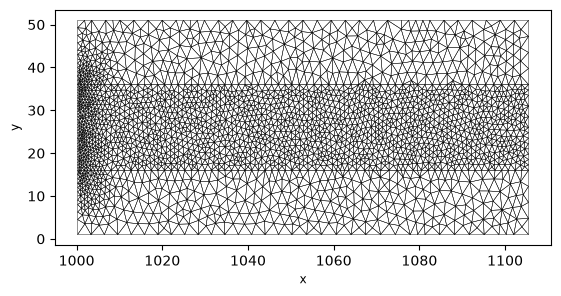

In [12]:
gdf.plot(edgecolor="black", facecolor="none", linewidth=0.3)


### Bounding polygon

`bounding_polygon()` dissolves the cells into a single shapely polygon of the meshed footprint — the gateway to the shapely/geopandas ecosystem for clipping and spatial joins.

In [13]:
poly = ds.bounding_polygon()
poly.geom_type, tuple(round(float(b), 3) for b in poly.bounds)

('Polygon', (1000.234, 1.0, 1105.469, 51.0))

### Circumcenters

`circumcenters()` returns an `(n_face, 2)` array of per-cell circumcenters — the points a finite-volume scheme places unknowns at. Defined only for **triangular** meshes, which this is.

In [14]:
cc = np.asarray(ds.circumcenters())
cc.shape, np.round(cc[:3], 3)

((4842, 2),
 array([[1097.787,   19.274],
        [1103.02 ,   20.08 ],
        [1055.3  ,   14.371]]))

### Exterior edges

`exterior_edges()` returns the node indices of the mesh **boundary** — the edges that belong to exactly one cell. Its length is a quick measure of how much perimeter the mesh has.

In [15]:
edges = np.asarray(ds.exterior_edges())
edges.shape, edges[:6].tolist()

((148,), [69, 86, 139, 153, 208, 220])

148 boundary-edge entries outline the irregular perimeter of the finite-element domain — every edge touching only one triangle. Interior edges, shared by two elements, are excluded.

### Cell adjacency and connected components

`sparse_adjacency()` is the cell-to-cell adjacency as a SciPy sparse matrix (`nnz` = twice the number of shared internal edges). `connected_components()` labels which cells are mutually reachable through that adjacency.

In [16]:
adj = ds.sparse_adjacency()
labels = np.asarray(ds.connected_components())
{"adjacency_shape": adj.shape, "nnz": int(adj.nnz),
 "n_components": int(np.unique(labels).size)}

{'adjacency_shape': (4842, 4842), 'nnz': 14378, 'n_components': 1}

A single connected component: the FE mesh is one contiguous domain, every element reachable from every other across shared edges. The high `nnz` reflects how densely interconnected a fine triangulation is.

### Subset by a bounding box

`subset_by_bounds(xmin, ymin, xmax, ymax)` keeps only the cells inside a window (note the four positional coordinates, not a tuple). We take the centred 60% window and plot the result — a clean clip that returns a new `UgridDataset`. (`crop(bbox=...)` does the same thing with a tuple argument.)

In [17]:
b = ds.bounds
cx, cy = (b[0] + b[2]) / 2, (b[1] + b[3]) / 2
hx, hy = (b[2] - b[0]) * 0.3, (b[3] - b[1]) * 0.3
sub = ds.subset_by_bounds(cx - hx, cy - hy, cx + hx, cy + hy)
{"full_n_face": ds.n_face, "subset_n_face": sub.n_face}

{'full_n_face': 4842, 'subset_n_face': 2071}

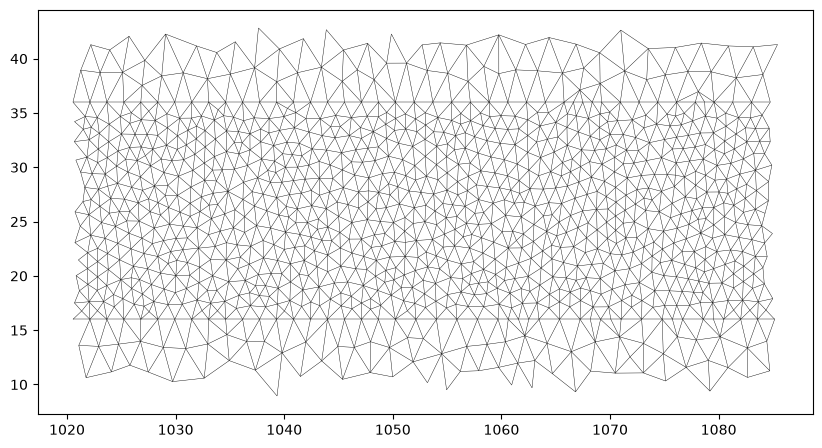

In [18]:
sub.plot_outline()


The centred window clips out a dense interior block of elements — a convenient way to isolate a sub-region of a large FE mesh for closer inspection while keeping a valid `UgridDataset`.

### Export: xarray and NetCDF round-trip

`to_xarray()` hands back an `xarray.Dataset` (the UGRID representation), and `to_file(path)` writes a NetCDF UGRID file — the canonical pyramids on-disk form that any UGRID reader can load back.

In [19]:
import tempfile, os
xds = ds.to_xarray()
out = os.path.join(tempfile.gettempdir(), "mesh_roundtrip.nc")
ds.to_file(out)
{"xarray_type": type(xds).__name__, "nc_bytes": os.path.getsize(out)}

{'xarray_type': 'Dataset', 'nc_bytes': 112528}

## 11. CRS-dependent operations — explain and skip

This format records **no CRS** (`crs` / `epsg` were `None` above), so coordinate-aware steps have nothing to work from:

- **`to_crs(...)`** — a reprojection needs a *source* CRS; with `None` there is nothing to reproject from, so we skip it. In practice you would first assign the CRS you know the model used.
- **`rasterize_like(...)` / `regrid(...)`** — these burn the mesh onto, or resample it to, a target **raster grid**. That is the job of the `pyramids-gis` raster layer (you supply a target `Dataset`); it is out of scope for a format-reader tutorial, so we only name it here.

In [20]:
ds.crs  # None -> no reprojection target; to_crs / rasterize_like / regrid skipped

## 12. Takeaway

- **FEFLOW `.fem` = finite-element groundwater mesh**: node list + element connectivity, read into a `UgridDataset`.
- This ATES sample is a dense all-triangular 2-D mesh (2496 nodes, 4842 faces; degree 3, no `-1` fill).
- Triangular, so `circumcenters()` works; no CRS, so reprojection/rasterisation are skipped.
- The full explore / plot / GIS toolbox applies unchanged once the mesh is a pyramids object.